## LAB 6 LIME IMPLEMENTATION

### Import libraries


In [2]:
import sklearn
import lime
import shap
import IPython

print("Scikit-learn:", sklearn.__version__)
print("LIME:", lime.__version__ if hasattr(lime, "__version__") else "Installed")
print("SHAP:", shap.__version__)
print("IPython:", IPython.__version__)

Scikit-learn: 1.7.2
LIME: Installed
SHAP: 0.52.0
IPython: 9.5.0


### Step 2 – Load the Wine Recognition dataset
- The Wine dataset is built into Scikit-learn, so we don't need to download any CSV file.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine

# Load the Wine dataset
wine = load_wine()

# Convert features into a DataFrame
X = pd.DataFrame(
    wine.data,
    columns=wine.feature_names
)

# Target variable
y = pd.Series(wine.target, name="Wine_Class")

# Display dataset
display(X.head())

print("Dataset shape:", X.shape)
print("Target shape:", y.shape)
print("Feature names:", wine.feature_names)
print("Target classes:", wine.target_names)

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


Dataset shape: (178, 13)
Target shape: (178,)
Feature names: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']
Target classes: ['class_0' 'class_1' 'class_2']


## 2. Exploratory Data Analysis

Exploratory Data Analysis (EDA) is performed to understand the structure and characteristics of the Wine Recognition dataset before training the classification models.

The following aspects are examined:

- **Dataset dimensions:** Determine the number of samples and input features.
- **Feature information:** Inspect the data types and identify the chemical attributes available for classification.
- **Missing values:** Check whether any features contain missing observations.
- **Class distribution:** Examine the number of samples belonging to each of the three wine categories.
- **Feature statistics:** Calculate descriptive statistics such as mean, standard deviation, minimum and maximum values.

This analysis helps identify the characteristics of the dataset and provides an initial understanding of the data that will be used for model training.

In [4]:
# Dataset dimensions
print("Dataset Shape:", X.shape)

# Feature information
print("\nDataset Information:")
display(X.info())

# Descriptive statistics
print("\nDescriptive Statistics:")
display(X.describe())

# Check missing values
print("\nMissing Values:")
display(X.isnull().sum())

# Class distribution
print("\nWine Class Distribution:")
display(y.value_counts().sort_index().rename(
    index=dict(enumerate(wine.target_names))
))

Dataset Shape: (178, 13)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 13 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline          

None


Descriptive Statistics:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000



Missing Values:


alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
dtype: int64


Wine Class Distribution:


Wine_Class
class_0    59
class_1    71
class_2    48
Name: count, dtype: int64

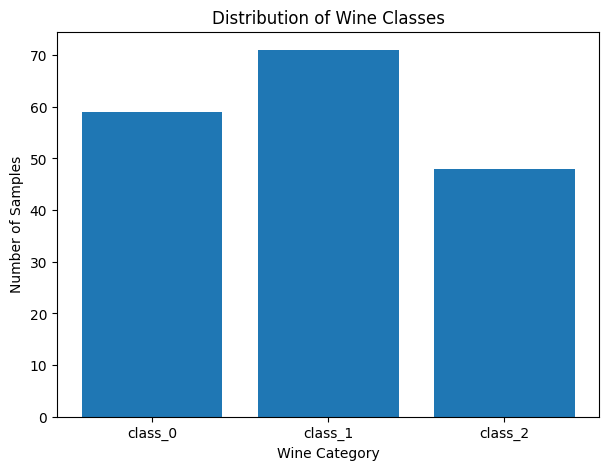

In [5]:
plt.figure(figsize=(7, 5))

class_counts = y.value_counts().sort_index()

plt.bar(
    wine.target_names,
    class_counts.values
)

plt.title("Distribution of Wine Classes")
plt.xlabel("Wine Category")
plt.ylabel("Number of Samples")
plt.show()

## 3. Splitting the Dataset

The dataset is divided into training and testing subsets to evaluate the classification models on previously unseen observations.

An 80:20 split is used, where 80% of the samples are allocated for training and the remaining 20% are reserved for testing.

The `train_test_split()` function from Scikit-learn is used to perform this division.

The following parameters are applied:

- **test_size = 0.2:** Allocates 20% of the dataset for testing.
- **random_state = 42:** Ensures that the same split can be reproduced.
- **stratify = y:** Maintains the original class proportions in both training and testing subsets.

Stratified splitting is particularly useful for classification tasks because it helps ensure that each subset contains a representative distribution of the three wine categories.

In [6]:
from sklearn.model_selection import train_test_split

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display dataset sizes
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining labels:", y_train.shape)
print("Testing labels:", y_test.shape)

# Check class distribution in both subsets
print("\nTraining class distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting class distribution:")
print(y_test.value_counts().sort_index())

Training features: (142, 13)
Testing features: (36, 13)

Training labels: (142,)
Testing labels: (36,)

Training class distribution:
Wine_Class
0    47
1    57
2    38
Name: count, dtype: int64

Testing class distribution:
Wine_Class
0    12
1    14
2    10
Name: count, dtype: int64


## 4. Data Preprocessing and Feature Scaling

Feature scaling is an important preprocessing step for certain machine learning algorithms. The chemical properties in the Wine dataset have different numerical ranges. For example, alcohol and magnesium have considerably different scales from measurements such as hue and proline-related attributes.

To ensure that differences in feature magnitudes do not disproportionately influence the classification process, standardisation is applied where required.

The `StandardScaler` transformation standardises each feature using its mean and standard deviation, producing values with an approximate mean of zero and standard deviation of one.

Feature scaling is particularly important for Logistic Regression because it relies on an optimisation process that can be affected by differences in feature magnitudes.

Decision Tree and Random Forest classifiers are tree-based algorithms and do not require feature scaling because their splitting decisions are based on feature thresholds.

Therefore, separate preprocessing pipelines will be used:
- **Decision Tree:** Uses the original feature values.
- **Random Forest:** Uses the original feature values.
- **Logistic Regression:** Applies standardisation before classification.

The scaler is fitted only on the training data through the pipeline, preventing information from the test set from influencing preprocessing.

In [7]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

# Decision Tree model
decision_tree = DecisionTreeClassifier(
    random_state=42
)

# Random Forest model
random_forest = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Logistic Regression with feature scaling
logistic_regression = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000))
])

print("All three classifiers have been initialised successfully.")

All three classifiers have been initialised successfully.


## 5. Training the Classification Models

In this stage, three supervised machine learning classification algorithms are trained using the prepared training dataset: Decision Tree, Random Forest and Logistic Regression.

Each algorithm learns the relationship between the chemical properties of wine samples and their corresponding target categories.

The models are trained using the same training data to ensure a consistent basis for performance comparison.

- **Decision Tree Classifier:** Builds a tree-like structure by selecting feature thresholds that help distinguish between the wine categories.
- **Random Forest Classifier:** Trains multiple decision trees on different subsets of the training data and combines their predictions.
- **Logistic Regression:** Learns class probabilities using a linear decision function. Standardisation is performed through its preprocessing pipeline before model fitting.

After training, all three models are ready to predict the wine categories of unseen samples from the testing dataset.

In [8]:
# Train Decision Tree
decision_tree.fit(X_train, y_train)

# Train Random Forest
random_forest.fit(X_train, y_train)

# Train Logistic Regression
logistic_regression.fit(X_train, y_train)

print("All three models have been trained successfully.")

All three models have been trained successfully.


## 6. Model Evaluation

After training the three classification models, their performance is evaluated using the test dataset. Multiple evaluation metrics are used to understand how effectively each model classifies wine samples into the three categories.

The evaluation metrics include:

- **Accuracy:** Measures the proportion of correctly classified samples.
- **Precision:** Measures how many samples predicted as a particular class actually belong to that class.
- **Recall:** Measures how effectively the model identifies samples belonging to each class.
- **F1-score:** Represents the harmonic mean of precision and recall.
- **ROC-AUC:** Evaluates the model's ability to distinguish between the three classes using predicted probabilities.

Weighted averages are used for precision, recall, and F1-score to account for the number of samples in each class.

In [9]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

models = {
    "Decision Tree": decision_tree,
    "Random Forest": random_forest,
    "Logistic Regression": logistic_regression
}

results = []

for name, model in models.items():
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, average="weighted", zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, average="weighted", zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_test, y_proba, multi_class="ovr", average="weighted"
        )
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Decision Tree,0.9444,0.9514,0.9444,0.945,0.9545
1,Random Forest,1.0000,1.0000,1.0000,1.000,1.0000
2,Logistic Regression,0.9722,0.9741,0.9722,0.972,1.0000


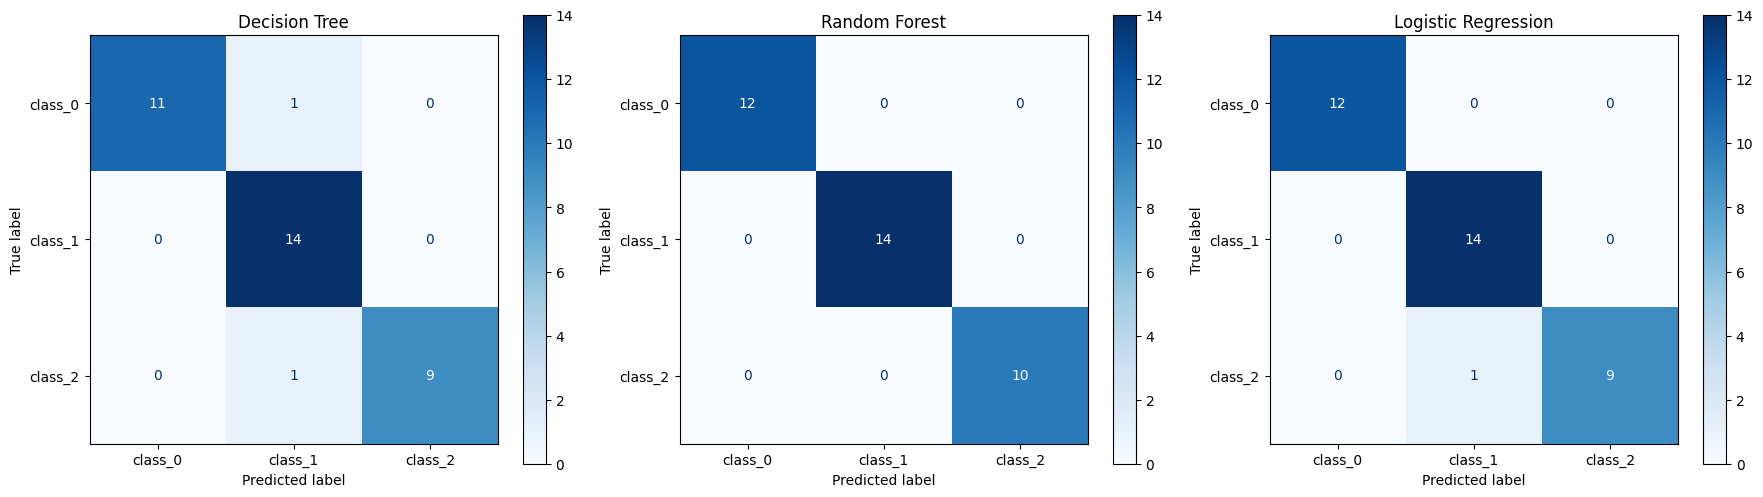

In [10]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, model) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_estimator(
        model,
        X_test,
        y_test,
        display_labels=wine.target_names,
        cmap="Blues",
        ax=ax
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()

### Interpretation of Model Performance

The evaluation results indicate that all three classification models performed effectively on the Wine Recognition dataset.

The Random Forest classifier achieved the highest performance, with 100% accuracy, precision, recall, F1-score, and ROC-AUC. It correctly classified all samples in the test dataset.

Logistic Regression achieved an accuracy of 97.22%, with only one misclassification. The Decision Tree classifier achieved an accuracy of 94.44%, with two misclassifications.

Based on the confusion matrices, Random Forest demonstrated the best classification performance on this particular test split, followed by Logistic Regression and Decision Tree.

Although Random Forest achieved perfect test results, further validation would be necessary to determine how consistently it performs on unseen data.

## 7. Individual Sample Prediction

To understand how the trained models classify individual wine samples, two observations are selected from the test dataset.

For each observation, the actual wine category, predicted category, and predicted probabilities are examined across all three classification models.

These selected observations will also be used later to generate local explanations using LIME and SHAP. The Decision Tree classifier is selected as the primary model for this explainability analysis.

In [11]:
# Select two observations from the test dataset
selected_samples = X_test.iloc[[0, 1]]
actual_classes = y_test.iloc[[0, 1]]

display(selected_samples)

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
10,14.10,2.16,2.30,18.0,105.0,2.95,3.32,0.22,2.38,5.75,1.25,3.17,1510.0
134,12.51,1.24,2.25,17.5,85.0,2.00,0.58,0.60,1.25,5.45,0.75,1.51,650.0


In [12]:
for position in range(len(selected_samples)):

    sample = selected_samples.iloc[[position]]

    actual_class = actual_classes.iloc[position]

    print(f"\n{'='*50}")
    print(f"Sample {position + 1}")
    print(f"{'='*50}")

    print("Actual Class:", wine.target_names[actual_class])

    for name, model in models.items():

        prediction = model.predict(sample)[0]
        probabilities = model.predict_proba(sample)[0]

        print(f"\n{name}")
        print("Predicted Class:", wine.target_names[prediction])

        probability_df = pd.DataFrame({
            "Wine Class": wine.target_names,
            "Probability": probabilities
        })

        display(probability_df)


Sample 1
Actual Class: class_0

Decision Tree
Predicted Class: class_0


,Wine Class,Probability
0,class_0,1.0
1,class_1,0.0
2,class_2,0.0



Random Forest
Predicted Class: class_0


,Wine Class,Probability
0,class_0,0.98
1,class_1,0.02
2,class_2,0.00



Logistic Regression
Predicted Class: class_0


,Wine Class,Probability
0,class_0,0.999671
1,class_1,0.000307
2,class_2,0.000023


... (2 outputs left out)


Random Forest
Predicted Class: class_2


,Wine Class,Probability
0,class_0,0.00
1,class_1,0.23
2,class_2,0.77



Logistic Regression
Predicted Class: class_1


,Wine Class,Probability
0,class_0,0.007051
1,class_1,0.540423
2,class_2,0.452526


## 8. LIME (Local Interpretable Model-Agnostic Explanations)

LIME is an explainability technique used to understand individual predictions made by machine learning models.

It works by generating perturbed variations of a selected input sample and observing how the trained model predicts those variations. Using these predictions, LIME builds a simple interpretable model around the selected observation.

The resulting explanation identifies the features that contribute positively or negatively towards the model's prediction.

In this experiment, LIME is applied to the Decision Tree classifier to understand the influence of chemical properties on individual wine classification predictions.

In [13]:
from lime.lime_tabular import LimeTabularExplainer

# Define class names
class_names = list(wine.target_names)

# Initialise LIME explainer
lime_explainer = LimeTabularExplainer(
    training_data=X_train.to_numpy(),
    feature_names=list(X_train.columns),
    class_names=class_names,
    mode="classification",
    discretize_continuous=True,
    random_state=42
)

print("LIME explainer initialised successfully.")

LIME explainer initialised successfully.


### 8.2 LIME Explanation for Sample 1

The first selected test observation is passed to the LIME explainer to understand the Decision Tree's classification.

The model correctly predicts the wine category as class_0. LIME generates perturbed versions of this observation and analyses how changes in the chemical properties influence the model's prediction.

The explanation highlights the chemical features that support or oppose the predicted class.

In [14]:
# Prediction function for LIME
def predict_proba_for_lime(data):
    data_df = pd.DataFrame(data, columns=X_train.columns)
    return decision_tree.predict_proba(data_df)


# Select Sample 1
sample_1 = X_test.iloc[0]

# Get actual and predicted classes
actual_class_1 = y_test.iloc[0]

predicted_class_1 = decision_tree.predict(
    X_test.iloc[[0]]
)[0]

print("Actual Class:", wine.target_names[actual_class_1])
print("Predicted Class:", wine.target_names[predicted_class_1])


# Generate LIME explanation
explanation_1 = lime_explainer.explain_instance(
    data_row=sample_1.to_numpy(),
    predict_fn=predict_proba_for_lime,
    labels=(predicted_class_1,),
    num_features=13,
    num_samples=5000
)

# Display feature contributions
print("\nLIME Feature Contributions:")
display(pd.DataFrame(
    explanation_1.as_list(label=predicted_class_1),
    columns=["Feature Condition", "Contribution"]
))

# Display LIME visualisation
from IPython.display import display, HTML

display(HTML(
    explanation_1.as_html(
        labels=[predicted_class_1]
    )
))

Actual Class: class_0
Predicted Class: class_0

LIME Feature Contributions:


,Feature Condition,Contribution
0,proline > 981.25,0.261337
1,flavanoids > 2.77,0.172856
2,4.64 < color_intensity <= 6.18,0.171107
3,1.81 < malic_acid <= 3.17,-0.053145
4,total_phenols > 2.80,-0.025783
5,od280/od315_of_diluted_wines > 3.16,0.014246
6,17.20 < alcalinity_of_ash <= 19.50,0.008056
7,alcohol > 13.56,-0.007473
8,proanthocyanins > 1.95,-0.007405
9,nonflavanoid_phenols <= 0.27,-0.007183


### Interpretation of LIME Explanation for Sample 1

The LIME explanation shows that the Decision Tree correctly classified Sample 1 as class_0 with a predicted probability of 100%.

Among the features supporting this prediction, proline had the highest positive contribution (0.261337), followed by flavanoids (0.172856) and color intensity (0.171107).

Some features had negative contributions. Malic acid (-0.053145) and total phenols (-0.025783) were the most notable features opposing the predicted class.

Overall, the explanation indicates that proline, flavanoids, and color intensity played the strongest positive roles in the local explanation of this prediction. Despite the presence of opposing contributions, the Decision Tree maintained its prediction of class_0.

These contributions represent the behaviour of the local surrogate model generated by LIME and should not be interpreted as causal relationships.

### 8.4 LIME Explanation for Sample 2

The second selected observation belongs to class_2, but the Decision Tree incorrectly classifies it as class_1.

LIME is applied to this observation to identify the chemical properties that influenced the incorrect prediction.

The explanation helps examine which features supported the predicted class and which features opposed it, providing insight into the model's classification behaviour.

In [15]:
# Select Sample 2
sample_2 = X_test.iloc[1]

# Get actual and predicted classes
actual_class_2 = y_test.iloc[1]

predicted_class_2 = decision_tree.predict(
    X_test.iloc[[1]]
)[0]

print("Actual Class:", wine.target_names[actual_class_2])
print("Predicted Class:", wine.target_names[predicted_class_2])

# Generate LIME explanation
explanation_2 = lime_explainer.explain_instance(
    data_row=sample_2.to_numpy(),
    predict_fn=predict_proba_for_lime,
    labels=(predicted_class_2,),
    num_features=13,
    num_samples=5000
)

# Display feature contributions
print("\nLIME Feature Contributions:")

display(pd.DataFrame(
    explanation_2.as_list(label=predicted_class_2),
    columns=["Feature Condition", "Contribution"]
))

# Display visualisation
display(HTML(
    explanation_2.as_html(
        labels=[predicted_class_2]
    )
))

Actual Class: class_2
Predicted Class: class_1

LIME Feature Contributions:


,Feature Condition,Contribution
0,4.64 < color_intensity <= 6.18,-0.271175
1,496.25 < proline <= 673.50,0.233823
2,flavanoids <= 1.23,-0.128525
3,17.20 < alcalinity_of_ash <= 19.50,-0.077020
4,malic_acid <= 1.61,0.053925
5,hue <= 0.78,0.040971
6,magnesium <= 88.00,-0.016683
7,1.71 < total_phenols <= 2.33,0.016614
8,12.37 < alcohol <= 13.01,-0.016030
9,2.20 < ash <= 2.36,0.012894


### Interpretation of LIME Explanation for Sample 2

The LIME explanation was generated for Sample 2, which actually belongs to class_2. However, the Decision Tree incorrectly predicted it as class_1 with a predicted probability of 100%.

The explanation indicates that proline had the strongest positive contribution (+0.2338) towards the predicted class. Malic acid (+0.0539) and hue (+0.0410) also supported the prediction.

On the other hand, color intensity (-0.2712) and flavanoids (-0.1285) had the strongest negative contributions, opposing the predicted class.

These contributions illustrate how different chemical properties influenced the model's local prediction. The result also demonstrates that a model can make an incorrect prediction with high confidence. LIME helps investigate the model's behaviour but does not establish causal relationships between chemical properties and wine categories.

## 9. Comparison of LIME Explanations

The LIME explanations generated for Sample 1 and Sample 2 are compared to understand how the Decision Tree uses different chemical properties when making individual predictions.

Sample 1 was correctly classified as class_0, whereas Sample 2 was incorrectly classified as class_1.

The comparison focuses on the features contributing positively and negatively to each prediction and examines the differences in their local influence.

In [16]:
# Extract LIME contributions for both samples
lime_sample_1 = pd.DataFrame(
    explanation_1.as_list(label=predicted_class_1),
    columns=["Feature Condition", "Sample 1"]
)

lime_sample_2 = pd.DataFrame(
    explanation_2.as_list(label=predicted_class_2),
    columns=["Feature Condition", "Sample 2"]
)

# Merge the explanations
lime_comparison = pd.merge(
    lime_sample_1,
    lime_sample_2,
    on="Feature Condition",
    how="outer"
).fillna(0)

display(lime_comparison.round(4))

,Feature Condition,Sample 1,Sample 2
0,1.71 < total_phenols <= 2.33,0.0000,0.0166
1,1.81 < malic_acid <= 3.17,-0.0531,0.0000
2,12.37 < alcohol <= 13.01,0.0000,-0.0160
3,17.20 < alcalinity_of_ash <= 19.50,0.0081,-0.0770
4,2.20 < ash <= 2.36,-0.0037,0.0129
5,4.64 < color_intensity <= 6.18,0.1711,-0.2712
6,496.25 < proline <= 673.50,0.0000,0.2338
7,97.00 < magnesium <= 107.75,-0.0014,0.0000
8,alcohol > 13.56,-0.0075,0.0000
9,flavanoids <= 1.23,0.0000,-0.1285


### 9.2 Interpretation of the Comparison

The comparison of the two LIME explanations reveals differences in how the Decision Tree uses chemical properties for individual predictions.

Proline contributed positively to both predictions, with values of 0.2613 for Sample 1 and 0.2338 for Sample 2.

However, color intensity showed opposite contributions. It supported the prediction for Sample 1 with a contribution of 0.1711 but opposed the prediction for Sample 2 with a contribution of -0.2712. A similar difference was observed for flavanoids, which contributed positively to Sample 1 and negatively to Sample 2.

Other features, including malic acid, alcalinity of ash, and total phenols, also showed differences in their contributions.

These observations demonstrate that feature importance can vary between individual predictions. LIME provides a local explanation of the model's behaviour around a particular observation, rather than a single explanation applicable to the entire dataset.

The comparison also highlights the importance of explainability in identifying how a model arrives at both correct and incorrect predictions.

In [17]:
explanation_2.save_to_file("lime_sample_2.html")

In [18]:
explanation_1.save_to_file("lime_sample_1.html")

## 9. SHAP (SHapley Additive exPlanations)

SHAP is an explainability technique used to understand how individual features influence a machine learning model's predictions.

It assigns each feature a SHAP value, indicating how much that feature contributes towards a prediction.

Unlike LIME, which creates a local approximation of the model, SHAP uses Shapley values from cooperative game theory to calculate feature contributions.

In [19]:
import shap

print("SHAP version:", shap.__version__)

# Initialise the SHAP TreeExplainer using the trained Decision Tree
shap_explainer = shap.TreeExplainer(decision_tree)

print("SHAP explainer initialised successfully.")

SHAP version: 0.52.0
SHAP explainer initialised successfully.


### 9.1 SHAP Explanation for Sample 1

In this step, SHAP is used to explain the Decision Tree's prediction for Sample 1.

The objective is to identify which chemical features contributed positively or negatively towards the predicted class.

Sample 1 was correctly classified by the Decision Tree as class_0.

In [20]:
# Generate SHAP values for Sample 1
sample_1_shap = X_test.iloc[[0]]

shap_values_1 = shap_explainer(sample_1_shap)

print("Actual class:", wine.target_names[y_test.iloc[0]])
print("Predicted class:", wine.target_names[decision_tree.predict(sample_1_shap)[0]])

Actual class: class_0
Predicted class: class_0


In [21]:
# Display SHAP values for Sample 1
shap_values_1

.values =
array([[[ 0.        ,  0.        ,  0.        ],
        [-0.00530587,  0.00530587,  0.        ],
        [-0.00347418,  0.00347418,  0.        ],
        [ 0.        , -0.00417892,  0.00417892],
        [ 0.        ,  0.        ,  0.        ],
        [ 0.        ,  0.        ,  0.        ],
        [ 0.32854338,  0.01888736, -0.34743074],
        [ 0.        ,  0.        ,  0.        ],
        [ 0.        ,  0.        ,  0.        ],
        [ 0.2569559 , -0.33260209,  0.07564618],
        [ 0.        ,  0.        ,  0.        ],
        [-0.0035446 ,  0.0035446 ,  0.        ],
        [ 0.09583946, -0.09583946,  0.        ]]])

.base_values =
array([[0.33098592, 0.40140845, 0.26760563]])

.data =
array([[1.41e+01, 2.16e+00, 2.30e+00, 1.80e+01, 1.05e+02, 2.95e+00,
        3.32e+00, 2.20e-01, 2.38e+00, 5.75e+00, 1.25e+00, 3.17e+00,
        1.51e+03]])

 ### 9.2 SHAP Waterfall Plot for Sample 1

The SHAP waterfall plot illustrates how each feature contributes to the model's prediction.

It starts with the baseline value and shows how individual feature contributions move the prediction towards or away from the final predicted class.

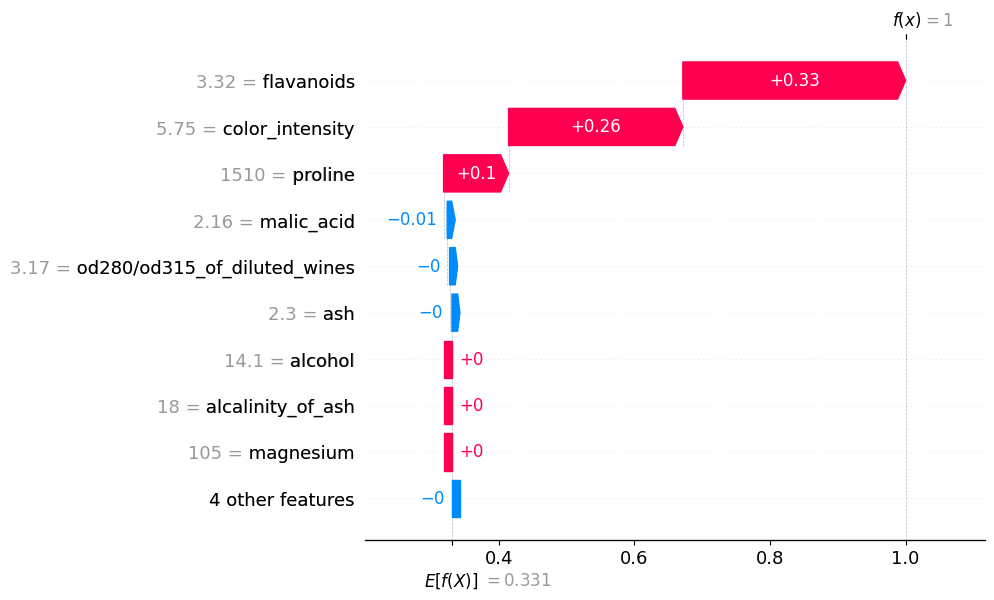

In [22]:
# Create SHAP waterfall plot for Sample 1, focusing on class_0
shap.plots.waterfall(shap_values_1[0, :, 0])

### Interpretation of SHAP Waterfall Plot for Sample 1

The SHAP waterfall plot explains the contribution of individual chemical features towards the Decision Tree's prediction for Sample 1.

The baseline value is 0.331, and the final prediction reaches 1.00 for class_0.

Flavanoids (+0.33) has the strongest positive contribution, followed by color intensity (+0.26) and proline (+0.10). These features strongly support the prediction of class_0.

Malic acid and a few other features have small negative contributions, slightly opposing the prediction.

Overall, the visualisation shows that flavanoids, color intensity and proline played the most important roles in the model's prediction for Sample 1.

In [24]:
# Select Sample 2
sample_2_shap = X_test.iloc[[1]]

# Generate SHAP values
shap_values_2 = shap_explainer(sample_2_shap)

# Display actual and predicted classes
print("Actual class:", wine.target_names[y_test.iloc[1]])
print("Predicted class:", wine.target_names[decision_tree.predict(sample_2_shap)[0]])

Actual class: class_2
Predicted class: class_1


### 9.3 SHAP Explanation for Sample 2

In this step, SHAP is used to explain the Decision Tree's prediction for Sample 2.

Sample 2 actually belongs to class_2, but the Decision Tree incorrectly predicted class_1.

The objective is to identify which chemical features influenced the model to make this incorrect prediction.

In [25]:
# Display SHAP values for Sample 2
shap_values_2

.values =
array([[[ 0.        ,  0.        ,  0.        ],
        [-0.01244325,  0.01244325,  0.        ],
        [-0.00347418,  0.00347418,  0.        ],
        [ 0.        ,  0.58765413, -0.58765413],
        [ 0.        ,  0.        ,  0.        ],
        [ 0.        ,  0.        ,  0.        ],
        [-0.19631571, -0.01541622,  0.21173193],
        [ 0.        ,  0.        ,  0.        ],
        [ 0.        ,  0.        ,  0.        ],
        [ 0.05394456, -0.16226113,  0.10831657],
        [ 0.        ,  0.        ,  0.        ],
        [-0.0035446 ,  0.0035446 ,  0.        ],
        [-0.16915274,  0.16915274,  0.        ]]])

.base_values =
array([[0.33098592, 0.40140845, 0.26760563]])

.data =
array([[1.251e+01, 1.240e+00, 2.250e+00, 1.750e+01, 8.500e+01, 2.000e+00,
        5.800e-01, 6.000e-01, 1.250e+00, 5.450e+00, 7.500e-01, 1.510e+00,
        6.500e+02]])

### Interpretation of SHAP Values for Sample 2

The SHAP explanation was generated for Sample 2, which actually belongs to class_2. However, the Decision Tree incorrectly predicted it as class_1 with a probability of 100%.

The SHAP values indicate that alcalinity of ash (+0.5877) had the strongest positive contribution towards the predicted class. Proline (+0.1692) also contributed positively.

On the other hand, color intensity (-0.1623) and flavanoids (-0.0154) had negative contributions, opposing the prediction.

Overall, the positive contributions outweighed the negative contributions, resulting in the model predicting class_1 instead of the actual class_2. This demonstrates how SHAP helps identify the features influencing an incorrect model prediction.

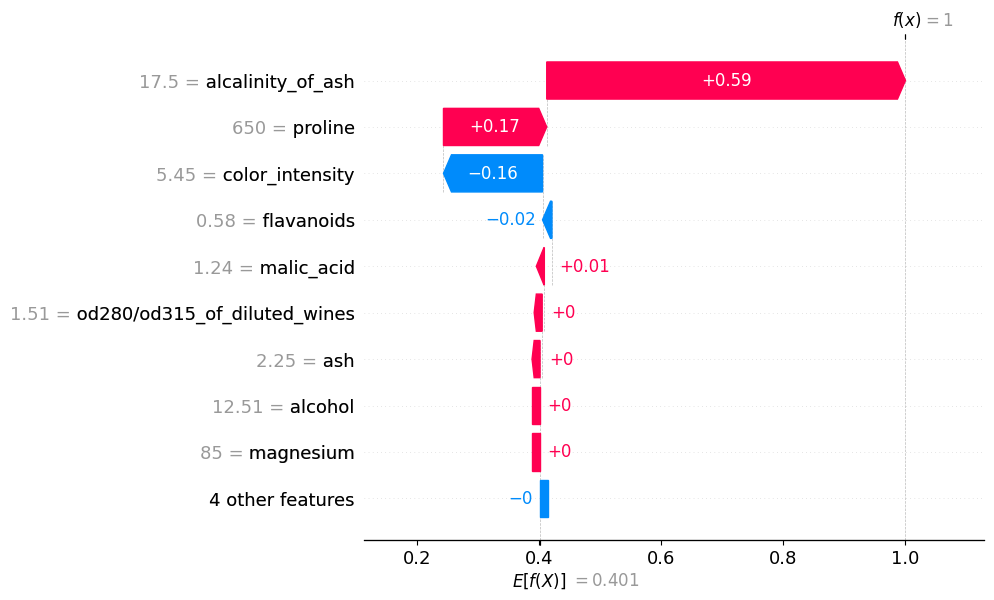

In [26]:
# Create SHAP waterfall plot for Sample 2
shap.plots.waterfall(shap_values_2[0, :, 1])

### 9.5 Global SHAP Feature Importance

Global SHAP analysis helps identify the features that have the greatest influence on the model's predictions across the test dataset.

Unlike local explanations, which focus on individual observations, global explanations provide an overall view of feature importance.

In [27]:
# Generate SHAP values for the entire test dataset
shap_values_global = shap_explainer(X_test)

print("Global SHAP values generated successfully.")
print("SHAP values shape:", shap_values_global.values.shape)

Global SHAP values generated successfully.
SHAP values shape: (36, 13, 3)


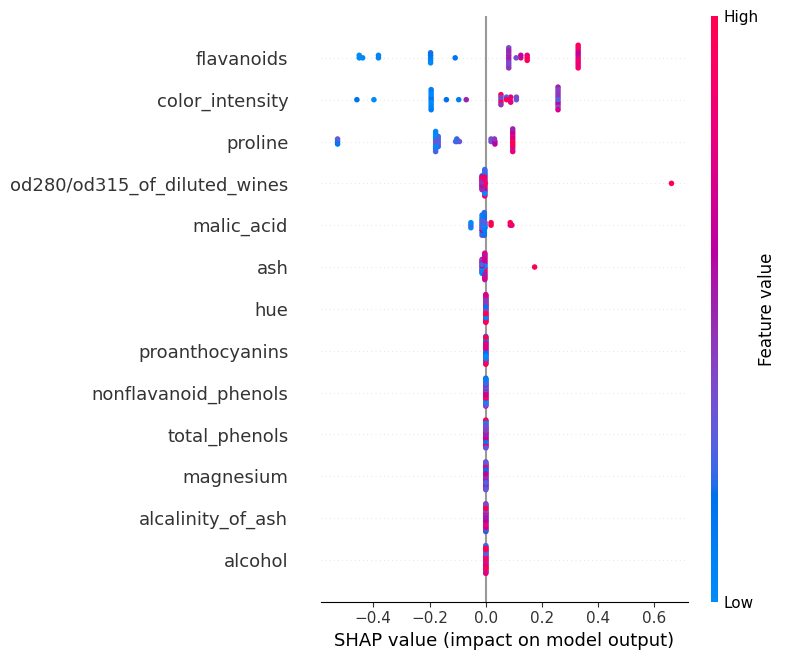

In [28]:
# Generate SHAP summary plot
shap.summary_plot(
    shap_values_global.values[:, :, 0],
    X_test,
    feature_names=X_test.columns
)

### 9.6 SHAP Summary Plot

The SHAP summary plot provides an overall view of how different chemical features influence the model's predictions across the test dataset.

It displays the importance of each feature based on its SHAP values and shows how the feature values influence the predictions.

Features are ranked according to their overall importance.

SHAP Summary Plot for class_0


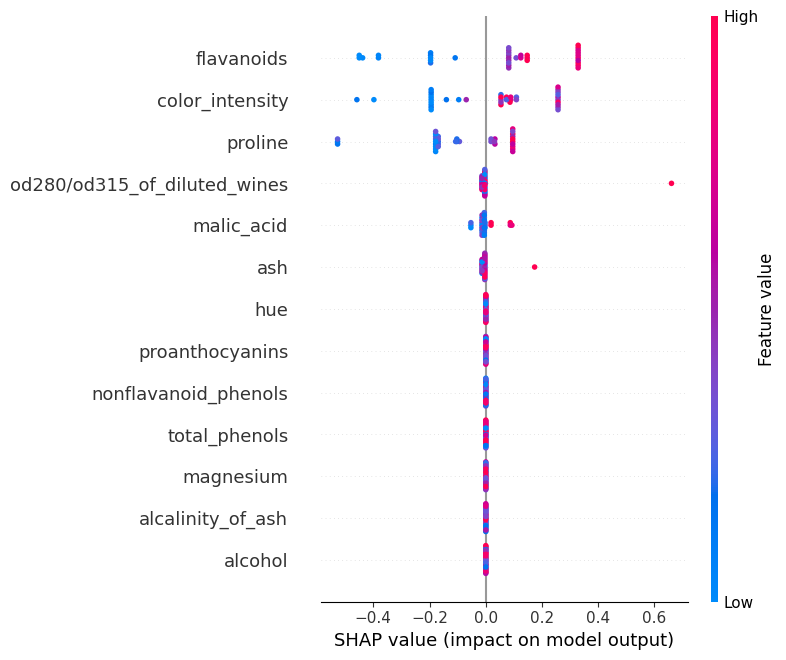

SHAP Summary Plot for class_1


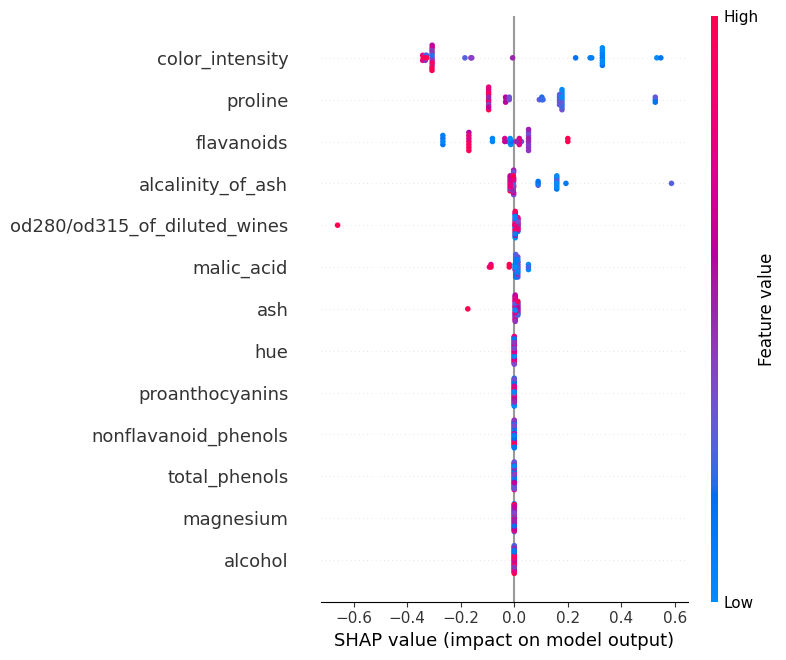

SHAP Summary Plot for class_2


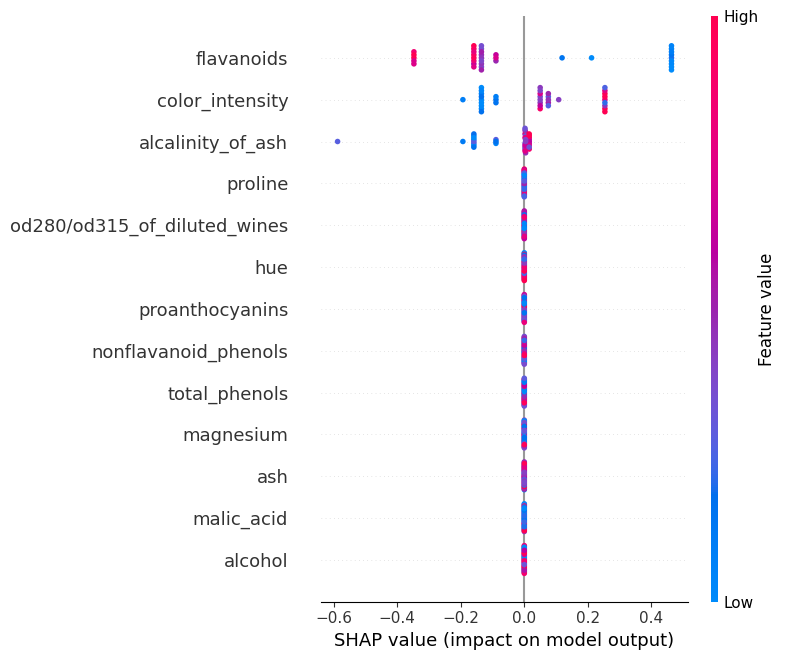

In [29]:
# Generate SHAP summary plots for all three wine classes

for class_index, class_name in enumerate(wine.target_names):
    print(f"SHAP Summary Plot for {class_name}")

    shap.summary_plot(
        shap_values_global.values[:, :, class_index],
        X_test,
        feature_names=X_test.columns
    )

In [30]:
# Extract SHAP values for the predicted class of each sample

sample_1_shap_values = shap_values_1.values[0, :, 0]
sample_2_shap_values = shap_values_2.values[0, :, 1]

# Create a comparison DataFrame
shap_comparison = pd.DataFrame({
    "Feature": X_test.columns,
    "Sample 1 (class_0)": sample_1_shap_values,
    "Sample 2 (class_1)": sample_2_shap_values
})

# Display comparison
display(shap_comparison.round(4))

,Feature,Sample 1 (class_0),Sample 2 (class_1)
0,alcohol,0.0000,0.0000
1,malic_acid,-0.0053,0.0124
2,ash,-0.0035,0.0035
3,alcalinity_of_ash,0.0000,0.5877
4,magnesium,0.0000,0.0000
5,total_phenols,0.0000,0.0000
6,flavanoids,0.3285,-0.0154
7,nonflavanoid_phenols,0.0000,0.0000
8,proanthocyanins,0.0000,0.0000
9,color_intensity,0.2570,-0.1623


### Comparison of SHAP Explanations for Sample 1 and Sample 2

The SHAP explanations for Sample 1 and Sample 2 show how different chemical features influenced the Decision Tree's predictions.

For Sample 1, the model correctly predicted class_0. Flavanoids (+0.3285) had the strongest positive contribution, followed by color intensity (+0.2570) and proline (+0.0958). These features strongly supported the prediction of class_0.

For Sample 2, the model incorrectly predicted class_1 instead of the actual class_2. Alcalinity of ash (+0.5877) had the strongest positive contribution, followed by proline (+0.1692). Color intensity (-0.1623) had a negative contribution, opposing the prediction.

The comparison shows that different chemical features influenced the predictions for the two samples. Flavanoids and color intensity were important positive contributors for Sample 1, whereas alcalinity of ash and proline were the main positive contributors for Sample 2.

Overall, SHAP helps us understand the individual feature contributions behind both correct and incorrect predictions. It also demonstrates that the importance of a feature can vary depending on the sample being explained.

In [31]:
# Get prediction probabilities for Sample 1
probabilities_1 = decision_tree.predict_proba(sample_1_shap)[0]

# Get SHAP contributions for the predicted class (class_0)
contributions_1 = shap_values_1.values[0, :, 0]

# Create explanation table
shap_sample_1_table = pd.DataFrame({
    "Feature": X_test.columns,
    "Feature Value": sample_1_shap.iloc[0].values,
    "SHAP Contribution": contributions_1
})

# Sort by absolute SHAP contribution
shap_sample_1_table["Importance"] = (
    shap_sample_1_table["SHAP Contribution"].abs()
)

shap_sample_1_table = shap_sample_1_table.sort_values(
    by="Importance", ascending=False
)

# Display prediction probabilities
print("Prediction Probabilities for Sample 1")
for class_name, probability in zip(wine.target_names, probabilities_1):
    print(f"{class_name}: {probability:.2f}")

# Display feature contributions
display(shap_sample_1_table.drop(columns="Importance").round(4))

Prediction Probabilities for Sample 1
class_0: 1.00
class_1: 0.00
class_2: 0.00


,Feature,Feature Value,SHAP Contribution
6,flavanoids,3.32,0.3285
9,color_intensity,5.75,0.2570
12,proline,1510.00,0.0958
1,malic_acid,2.16,-0.0053
11,od280/od315_of_diluted_wines,3.17,-0.0035
2,ash,2.30,-0.0035
0,alcohol,14.10,0.0000
3,alcalinity_of_ash,18.00,0.0000
4,magnesium,105.00,0.0000
5,total_phenols,2.95,0.0000


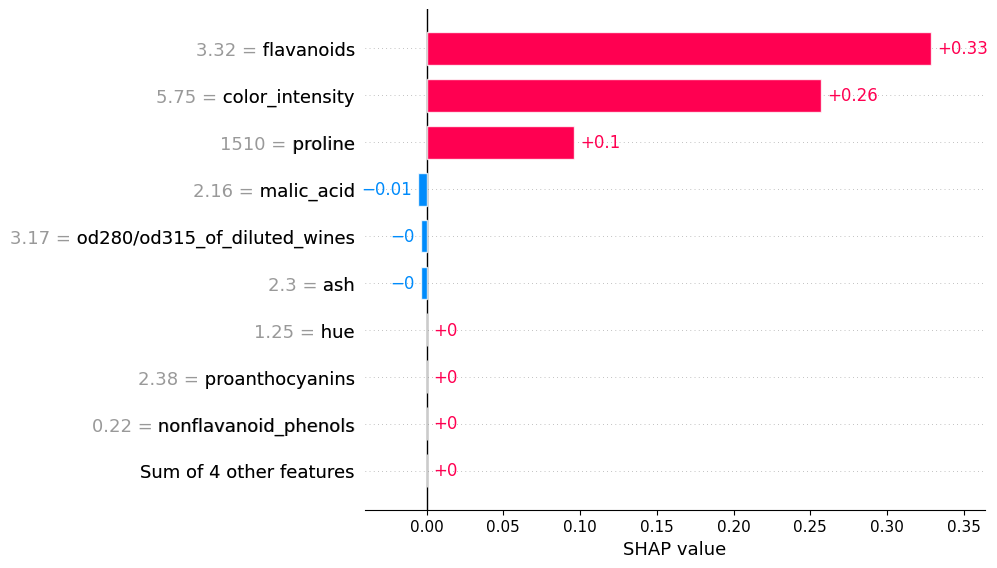

In [32]:
# SHAP bar plot for Sample 1
shap.plots.bar(shap_values_1[0, :, 0])

In [33]:
# Get prediction probabilities for Sample 2
probabilities_2 = decision_tree.predict_proba(sample_2_shap)[0]

# Get SHAP contributions for the predicted class (class_1)
contributions_2 = shap_values_2.values[0, :, 1]

# Create explanation table
shap_sample_2_table = pd.DataFrame({
    "Feature": X_test.columns,
    "Feature Value": sample_2_shap.iloc[0].values,
    "SHAP Contribution": contributions_2
})

# Sort by absolute SHAP contribution
shap_sample_2_table["Importance"] = (
    shap_sample_2_table["SHAP Contribution"].abs()
)

shap_sample_2_table = shap_sample_2_table.sort_values(
    by="Importance", ascending=False
)

# Display prediction probabilities
print("Prediction Probabilities for Sample 2")
for class_name, probability in zip(wine.target_names, probabilities_2):
    print(f"{class_name}: {probability:.2f}")

# Display feature contributions
display(shap_sample_2_table.drop(columns="Importance").round(4))

Prediction Probabilities for Sample 2
class_0: 0.00
class_1: 1.00
class_2: 0.00


,Feature,Feature Value,SHAP Contribution
3,alcalinity_of_ash,17.50,0.5877
12,proline,650.00,0.1692
9,color_intensity,5.45,-0.1623
6,flavanoids,0.58,-0.0154
1,malic_acid,1.24,0.0124
11,od280/od315_of_diluted_wines,1.51,0.0035
2,ash,2.25,0.0035
0,alcohol,12.51,0.0000
4,magnesium,85.00,0.0000
5,total_phenols,2.00,0.0000


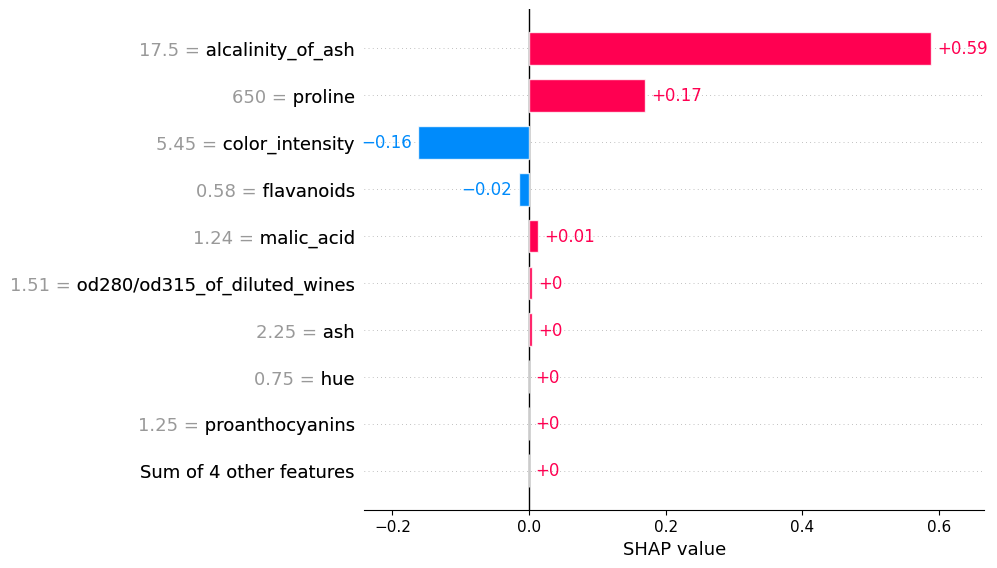

In [35]:
# SHAP bar plot for Sample 2
shap.plots.bar(shap_values_2[0, :, 1])

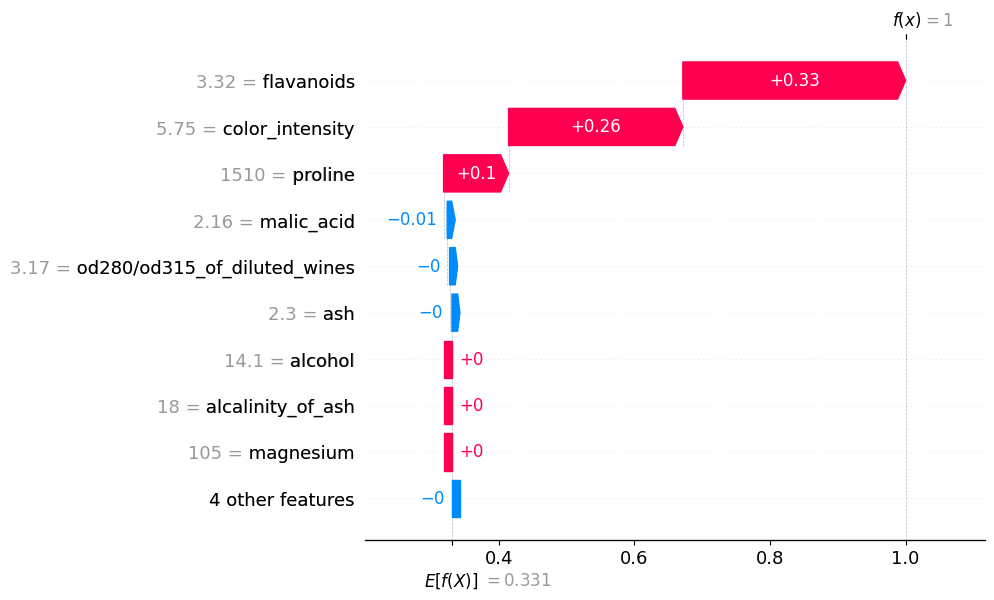

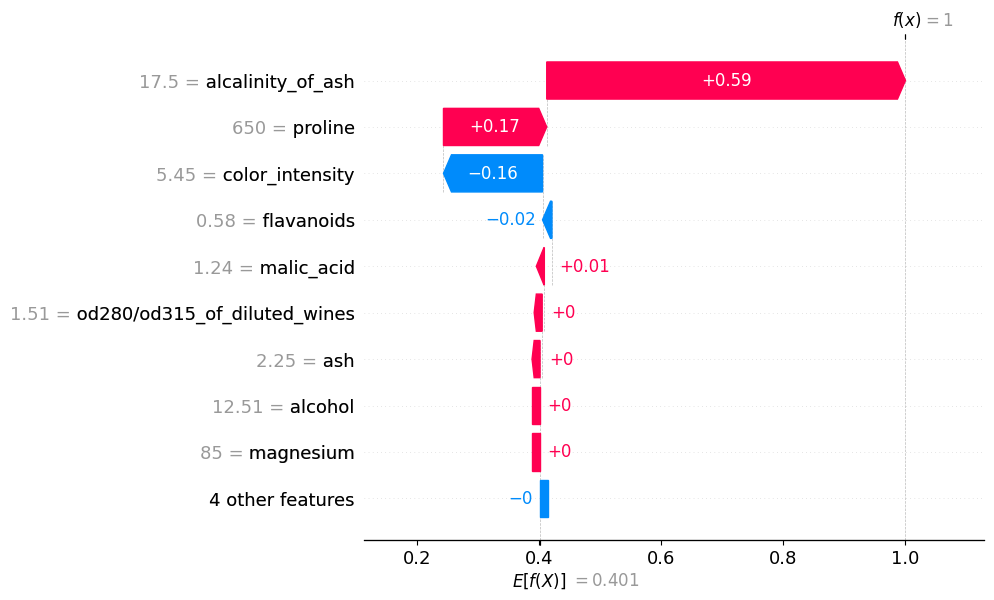

In [36]:
# SHAP waterfall plot for Sample 1
shap.plots.waterfall(shap_values_1[0, :, 0])

# SHAP waterfall plot for Sample 2
shap.plots.waterfall(shap_values_2[0, :, 1])

### 9.8 Comparison of LIME and SHAP Explanations

LIME and SHAP are two explainability techniques used to understand the predictions made by machine learning models.

LIME explains predictions by creating a local approximation of the model around an individual sample. SHAP uses Shapley values to calculate the contribution of individual features towards a prediction.

Both techniques were applied to the same Decision Tree model and the same two test samples.

The following comparison examines how both techniques explain the correct prediction for Sample 1 and the incorrect prediction for Sample 2.

### Interpretation of LIME and SHAP Comparison

The comparison shows that both LIME and SHAP provide useful explanations for understanding the Decision Tree's predictions.

For Sample 1, both techniques identified proline, flavanoids and color intensity as important features supporting the prediction of class_0. However, their ranking of these features differed.

For Sample 2, both techniques identified proline as a positive contributor and color intensity as a negative contributor towards the predicted class_1. SHAP additionally identified alcalinity of ash as the strongest positive contributor, while LIME highlighted the influence of other chemical features.

Although both techniques explain the same model predictions, their feature contributions and rankings can differ because they use different approaches to explain the model.

Overall, LIME and SHAP help improve the interpretability of machine learning models by explaining the factors influencing individual predictions, including incorrect predictions.

### Comparison of LIME and SHAP

LIME and SHAP are both explainable AI techniques used to understand the predictions made by machine learning models. Although both methods identified similar important features in our Wine Recognition experiment, their approaches to calculating feature contributions are different.

LIME explains individual predictions by creating perturbed samples and observing how changes in input features affect the model's output. SHAP uses concepts from game theory to calculate the contribution of individual features towards a prediction relative to a baseline.

In our experiment, both methods identified features such as flavanoids, color intensity and proline as important for Sample 1. However, the contribution values differed because the two techniques use different calculation methods.

LIME is useful when we need a quick, model-independent explanation of an individual prediction. SHAP is useful when we need detailed feature contribution analysis and want to study both individual predictions and overall feature importance.

Therefore, both techniques are useful for model interpretability, and using them together provides a more comprehensive understanding of how a machine learning model makes its predictions.


| Feature | LIME Contribution | SHAP Contribution |
|---|---:|---:|
| Flavanoids | +0.1729 | +0.3285 |
| Color intensity | +0.1711 | +0.2570 |
| Proline | +0.2613 | +0.0958 |